In [1]:
from itertools import islice
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def uniform_triangle(u, v):
    while True:
        s = np.random.uniform()
        t = np.random.uniform()
        in_triangle = s + t <= 1
        p = s * u + t * v if in_triangle else (1 - s) * u + (1 - t) * v
        yield p


triangle_set1 = [
    np.array([[0, 0], [0.5, 0.5], [0, 0.5]]),
    np.array([[0, 1], [0.5, 0.5], [0, 0.5]]),
]
triangle_set2 = [np.concatenate((a[:, 1:2], a[:, 0:1]), axis=1) for a in triangle_set1]

triangle_set = triangle_set1 + triangle_set2

[[0.16666667 0.33333333]
 [0.16666667 0.66666667]
 [0.33333333 0.16666667]
 [0.66666667 0.16666667]
 [1.         0.        ]
 [0.         1.        ]]


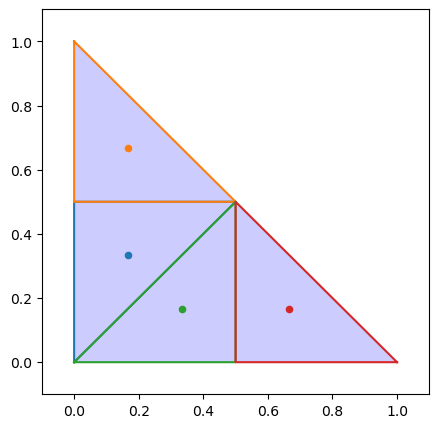

In [2]:
np.random.seed(42)

fig, ax = plt.subplots(figsize=(5, 5))
point_total = []

for triangle in triangle_set:
    # draw the triangle
    x_coords, y_coords = zip(*triangle)
    # Close the triangle by adding the first vertex at the end
    x_coords += (x_coords[0],)
    y_coords += (y_coords[0],)

    # Create the plot
    ax.plot(x_coords, y_coords)  # 'o' for circle markers at the vertices
    ax.fill(
        x_coords, y_coords, "b", alpha=0.2
    )  # Fill the triangle with a blue color and some transparency

    it = uniform_triangle(
        triangle[1] - triangle[0],
        triangle[2] - triangle[0],
    )
    # points = np.array(list(islice(it, 0, 7))) + triangle[0]
    points = triangle.mean(axis=0).reshape(-1, 2)

    ax.scatter(points[:, 0], points[:, 1], s=20)
    ax.set_xlim(-0.1, 1.1)
    ax.set_ylim(-0.1, 1.1)

    point_total.append(points)

point_total.append(np.array([[1,0]]))
point_total.append(np.array([[0,1]]))
point_total = np.concatenate(point_total)

print(point_total)

In [3]:
point_total

array([[0.16666667, 0.33333333],
       [0.16666667, 0.66666667],
       [0.33333333, 0.16666667],
       [0.66666667, 0.16666667],
       [1.        , 0.        ],
       [0.        , 1.        ]])

In [4]:
metal_combo = np.array(
    [
        ["Co", "Mo"],
    ]
)

np.random.seed(42)
candidates_total = []
for metal_combo_temp in metal_combo:
    a_temp = point_total.copy()
    np.random.shuffle(a_temp)
    candidates = np.around(
        np.concatenate((a_temp * 18 + 1, 20 - (a_temp * 18 + 1).sum(axis = 1).reshape(-1,1)), axis=1), 2
    )
    candidates_total.append(candidates)
    print(metal_combo_temp)
    print(candidates)

['Co' 'Mo']
[[ 4.  7.  9.]
 [ 4. 13.  3.]
 [ 1. 19.  0.]
 [ 7.  4.  9.]
 [19.  1.  0.]
 [13.  4.  3.]]


In [5]:
_all_candidates = []
# export the json file
# set a repeat experiment as a reference
repeat_exp = pd.DataFrame(
    {
        "substance1": ["Co"],
        "volume1": [20*6/8],
        "substance2": ["Mo"],
        "volume2": [20*1/8],
        "substance3": ["Na3Cit"],
        "volume3": [20*1/8],
        
        "syn_completed": ["None"],
        "storage_location": ["None"],
        "in_storage": ["None"],
        "cat_completed": ["None"], 
        
        "lsv_overpotential_-0.01": ["None"],
        "lsv_overpotential_-0.02": ["None"],
        "lsv_overpotential_-0.03": ["None"],
        "lsv_overpotential_-0.04": ["None"],
        "lsv_overpotential_-0.05": ["None"],

        "mass_time_start": ["None"],
        "mass_time_end": ["None"],
        "separation_coefficient":["None"]
    }
)

repeat_index = [0]

# write the new candidates to the excel for the closed-loop discovery
exp_data_out = {}
exp_data_out["substance1"] = []
exp_data_out["volume1"] = []
exp_data_out["substance2"] = []
exp_data_out["volume2"] = []
exp_data_out["substance3"] = []
exp_data_out["volume3"] = []

exp_data_out["syn_completed"] = []
exp_data_out["storage_location"] = []
exp_data_out["in_storage"] = []

exp_data_out["cat_completed"] = []
exp_data_out["lsv_overpotential_-0.01"] = []
exp_data_out["lsv_overpotential_-0.02"] = []
exp_data_out["lsv_overpotential_-0.03"] = []
exp_data_out["lsv_overpotential_-0.04"] = []
exp_data_out["lsv_overpotential_-0.05"] = []

exp_data_out["mass_time_start"] = []
exp_data_out["mass_time_end"] = []
exp_data_out["separation_coefficient"] = []

exp_data_out = pd.DataFrame(exp_data_out)

for candidate_index in range(len(candidates_total[0])):
    metal_index = 0
    if len(exp_data_out)%4 ==3:
        exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)

    temp = pd.DataFrame(
        {
            "substance1": [metal_combo[metal_index][0]],
            "volume1": [candidates_total[metal_index][candidate_index][0]],
            "substance2": [metal_combo[metal_index][1]],
            "volume2": [candidates_total[metal_index][candidate_index][1]],
            "substance3": "Na3Cit",
            "volume3": [candidates_total[metal_index][candidate_index][2]],

            "syn_completed": ["None"],
            "storage_location": ["None"],
            "in_storage": ["None"],
            "cat_completed": ["None"], 
            "lsv_overpotential_-0.01": ["None"],
            "lsv_overpotential_-0.02": ["None"],
            "lsv_overpotential_-0.03": ["None"],
            "lsv_overpotential_-0.04": ["None"],
            "lsv_overpotential_-0.05": ["None"],


            "mass_time_start": ["None"],
            "mass_time_end": ["None"],
            "separation_coefficient":["None"]
        }
    )

    for repeat in range(1):
        exp_data_out = pd.concat((exp_data_out, temp), ignore_index=True)
            
    # if len(exp_data_out) in repeat_index:
    #     exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)
exp_data_out = pd.concat((exp_data_out, repeat_exp), ignore_index=True)
display(exp_data_out)
exp_data_out.to_json(f"./initial_sampling_Co_Mo.json", indent = 4)

,substance1,volume1,substance2,volume2,substance3,volume3,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05,mass_time_start,mass_time_end,separation_coefficient
0,Co,4.0,Mo,7.0,Na3Cit,9.0,None,None,None,None,None,None,None,None,None,None,None,None
1,Co,4.0,Mo,13.0,Na3Cit,3.0,None,None,None,None,None,None,None,None,None,None,None,None
2,Co,1.0,Mo,19.0,Na3Cit,0.0,None,None,None,None,None,None,None,None,None,None,None,None
3,Co,15.0,Mo,2.5,Na3Cit,2.5,None,None,None,None,None,None,None,None,None,None,None,None
4,Co,7.0,Mo,4.0,Na3Cit,9.0,None,None,None,None,None,None,None,None,None,None,None,None
5,Co,19.0,Mo,1.0,Na3Cit,0.0,None,None,None,None,None,None,None,None,None,None,None,None
6,Co,13.0,Mo,4.0,Na3Cit,3.0,None,None,None,None,None,None,None,None,None,None,None,None
7,Co,15.0,Mo,2.5,Na3Cit,2.5,None,None,None,None,None,None,None,None,None,None,None,None


In [6]:
exp_data_out

,substance1,volume1,substance2,volume2,substance3,volume3,syn_completed,storage_location,in_storage,cat_completed,lsv_overpotential_-0.01,lsv_overpotential_-0.02,lsv_overpotential_-0.03,lsv_overpotential_-0.04,lsv_overpotential_-0.05,mass_time_start,mass_time_end,separation_coefficient
0,Co,4.0,Mo,7.0,Na3Cit,9.0,None,None,None,None,None,None,None,None,None,None,None,None
1,Co,4.0,Mo,13.0,Na3Cit,3.0,None,None,None,None,None,None,None,None,None,None,None,None
2,Co,1.0,Mo,19.0,Na3Cit,0.0,None,None,None,None,None,None,None,None,None,None,None,None
3,Co,15.0,Mo,2.5,Na3Cit,2.5,None,None,None,None,None,None,None,None,None,None,None,None
4,Co,7.0,Mo,4.0,Na3Cit,9.0,None,None,None,None,None,None,None,None,None,None,None,None
5,Co,19.0,Mo,1.0,Na3Cit,0.0,None,None,None,None,None,None,None,None,None,None,None,None
6,Co,13.0,Mo,4.0,Na3Cit,3.0,None,None,None,None,None,None,None,None,None,None,None,None
7,Co,15.0,Mo,2.5,Na3Cit,2.5,None,None,None,None,None,None,None,None,None,None,None,None


In [1]:
import sympy as sp

# Define the variable
x = sp.symbols('x')

# Define the equation
equation = sp.Eq(8*x, 3.8*(99.986 - 2*x)*(0.015 - 2*x))

# Solve the equation
solutions = sp.solve(equation, x)
solutions

[0.00742185269421905, 50.5193939367795]

In [4]:
0.00742185269421905*2

0.0148437053884381

In [3]:
(0.015-2*0.00742185269421905)/2


7.81473057809498e-05